# U2-L2：传感器速览

**课程目标**

1. 能说明 K1 上相机、IMU、里程计、关节、电池五类数据各自测的是什么，以及它们对应的 ROS2 消息类型。
2. 能比较「快照式取数」与「订阅式取数」两种读取方式，说明各自适合什么场合。
3. 能使用 SDK 的快照接口采集图像尺寸、姿态角、位置、电量，并读出这些数字的含义。
4. 能说明 `subscribe_image()` 与 `ros2 topic echo` 的关系：两者都是订阅者，区别只在于入口是 Python 还是命令行。


## 课程大纲映射（审核用）

| 轻任务 | 对应 cell | 核心概念 | 轻量概念 |
| --- | --- | --- | --- |
| ② 传感器速览：依次采集并打印图像尺寸、RPY、位置、电量% | 实验二 2.1、实验三 3.1–3.4 | 消息类型（`sensor_msgs/Image`、`sensor_msgs/Imu`、`nav_msgs/Odometry`） | — |
| `subscribe_image()` 本质是创建 ROS2 订阅者 | 实验二 2.2 | C04 订阅 | E02 回调 |

> 本映射块用于大纲对齐审核；导出 PDF 版本时移除此块。


## 一、传感器的数据也在话题上

上一课用 `ros2 topic list` 看到系统里有一堆话题，用 `hz` 测到图像话题一秒能出几十条消息。

### 1.1 五类数据，五种消息类型

| 传感器 | 测的是什么 | 话题上的消息类型 | SDK 里读到的对象 |
| --- | --- | --- | --- |
| 相机 | 前方的画面，一秒约 30 帧 | `sensor_msgs/msg/Image` | `Image` |
| IMU | 自身的加速度、转动快慢 | `sensor_msgs/msg/Imu` | `IMUState` |
| 里程计 | 走了多远、朝哪个方向 | `nav_msgs/msg/Odometry` | `OdomState` |
| 关节 | 每个关节的角度、速度、力矩 | `sensor_msgs/msg/JointState` | `JointStates` |
| 电池 | 剩余电量、电压、充放电状态 | `sensor_msgs/msg/BatteryState` | `BatteryState` |

消息里的字段名，和 SDK 对象里的属性名是同一套：
- 命令行里用 `ros2 topic echo` 看到的 `width`、`height`、`encoding`；
- 在 Python 里就是 `img.width`、`img.height`、`img.encoding`。

### 1.2 两种取数方式：快照与订阅

**快照式**：调用一次 `get_image()`、`get_imu()` 这类接口，拿回当前最新的一帧，调用完就结束。像举起手机拍一张照片，适合「我现在看一眼是多少」。

**订阅式**：调用一次 `subscribe_image(回调)` 把函数注册上去，之后每来一帧，SDK 自动帮你跑一次这个函数，直到你退订。像装了监控，画面自己推过来，适合「我要一直盯着，来一帧处理一帧」。

收到消息时自动跑的那段函数叫回调。`subscribe_image()` 要传进去的，就是这样一段函数。


## 二、连接 K1，读相机

**实验名称**：传感器速览

**实验目标**：采集 K1 相机的一帧图像，读出它的尺寸与像素编码；订阅相机两秒，数出一共收到多少帧；再依次读出 IMU 的加速度与角速度、里程计的位置与朝向、关节的角度、电池的剩余电量。

⚠️ **安全**：本课全程只读取传感器数据，**不发送任何运动 / 动作指令**，因此不需要让机器人进入 walk 模式。机器人放在地面，保持坐姿或趴姿即可；实验过程中无需搬动机器人。

**前置准备**：K1 已开机并与电脑建立连接（见 U1-L1）；已完成 U2-L1，会用 `ros2 topic list` 查看话题。

### 2.1 连接机器人


In [31]:
from boosteros.robots.booster import BoosterRobot

robot = BoosterRobot()
print("已连接 K1")

[Booster OS] [boosteros.sdk] [INFO] SDK Channel initialized on default


[Booster OS] [boosteros.sdk] [INFO] Starting Booster SDK Local Adapter (mode=local, network_interface=default, virtual_robot_name=default).


[Booster OS] [boosteros.sdk] [INFO] Booster SDK Local Adapter started (mode=local, network_interface=default).


Network interface not specified. Will use environment variable (FASTRTPS_DEFAULT_PROFILES_FILE).
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024


[Booster OS] [boosteros.robot] [INFO] Fetching camera configuration from API...


...

[Booster OS] [boosteros.BoosterSpeechRuntime] [INFO] Booster speech runtime initialized for robot_name=''


ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024


[Booster OS] [boosteros.BoosterAudioManager] [INFO] BoosterAudioManager initialized


[Booster OS] [boosteros.robot] [INFO] Booster OS resources initialized.


ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
已连接 K1


### 2.2 抓一帧图像

`get_image()` 调用一次，拿回相机此刻最新的一帧。把 `img` 单独写在单元格最后一行，Jupyter 会把它显示成图片。


尺寸： 544 × 448
编码： bgr8
时间戳： 1788239995.096


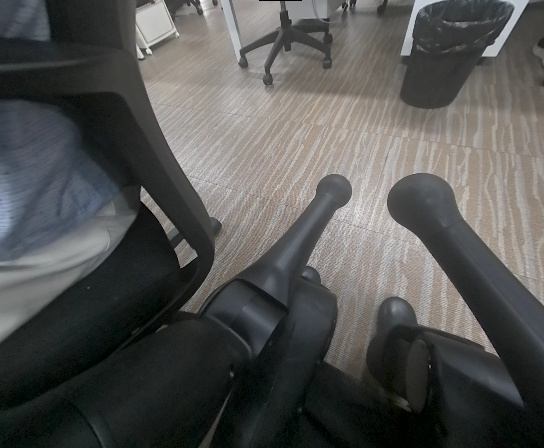

In [32]:
img = robot.get_image()  # 抓一帧彩色图

print("尺寸：", img.width, "×", img.height)
print("编码：", img.encoding)
print("时间戳：", round(img.header.timestamp, 3))

img  # 写在最后一行，Jupyter 直接把这帧图显示出来

图像的关键信息：
- `width` 和 `height` 是画面的宽高像素数。
- `encoding` 说明像素怎么排列，这个字段在处理图像时要用，通道顺序弄反了，颜色会出错。
  - `rgb8` 表示每个像素按红、绿、蓝三个通道各占 1 字节存放，
  - `bgr8` 则是蓝、绿、红的顺序。


### 2.3 深度图（选做）

同一个函数换一个参数，拿到的就是深度图——它记录的不是颜色，而是每个像素离相机有多远。


尺寸： 544 × 448
编码： mono16


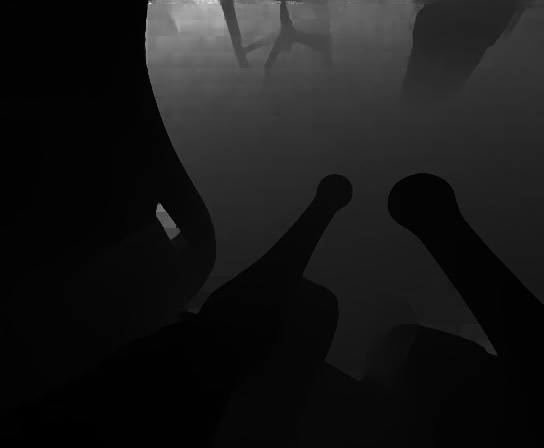

In [ ]:
try:
    depth = robot.get_image(img_type="depth")
    print("尺寸：", depth.width, "×", depth.height)
    print("编码：", depth.encoding)
except Exception as e:
    print("这次没取到深度图：", e)
depth  # 写在最后一行，Jupyter 直接把这帧图显示出来

### 2.4 订阅相机两秒

下面注册一个回调，让它跑两秒，数一数这两秒里来了多少帧。


In [35]:
import time

frames = []


def on_frame(img):
    """每收到一帧就跑一次，这里只记下它自带的时间戳。"""
    frames.append(img.header.timestamp)


sub = robot.subscribe_image(on_frame)    # 注册回调，本质是建一个订阅者
print("已订阅相机，等 2 秒……")
time.sleep(2)
sub.unsubscribe()                        # 用完退订，不再接收

print("2 秒内收到", len(frames), "帧")

已订阅相机，等 2 秒……


2 秒内收到 26 帧


`subscribe_image()` 是在相机的图像话题上建一个订阅者。

> 上一课的 `ros2 topic echo /boostercamera/head/rgb` 也是订阅，只不过它把消息打印在终端里；这里换成了你自己写的函数去订阅处理。

退订别漏：不退订，回调会一直跑，占着通道也占着算力。

把这里数出来的帧数除以 2，和上一课 `ros2 topic hz` 测到的帧率比一比，两个数字应该差不多。


## 三、IMU、里程计、关节与电池

<font color="red">下面继续只读传感器数据，不发送运动 / 动作指令，机器人不需要进入 walk 模式。</font> 实验过程中如有必要，保持现有姿势适当拖动机器人即可。

### 3.1 IMU：加速度与角速度

IMU 装在机器人躯干里，测量两个量：
- `linear_acceleration` 是三个方向上的加速度（m/s²）；
- `angular_velocity` 是绕三个方向转动的快慢（rad/s）。


In [37]:
imu = robot.get_imu()

print("坐标系：", imu.frame_id)
print("线加速度 (m/s²)：", imu.linear_acceleration)
print("角速度 (rad/s)：", imu.angular_velocity)
print("时间戳：", round(imu.timestamp, 3))

坐标系： trunk_link
线加速度 (m/s²)： [-1.69908706  0.93165    10.74617074]
角速度 (rad/s)： [-5.02448974e-02  4.74999296e-01 -2.51685719e-04]
时间戳： 1788240099.261


机器人静止不动时，加速度里有一个轴的读数接近 9.8，那是重力。把它轻轻抬起、倾斜一下，三个轴的读数会重新分配；晃动的时候，角速度里会出现明显的数字。

`frame_id` 标出这组数据是相对哪个坐标系量出来的，读数据时先看它，才知道 x、y、z 分别朝哪。


### 3.2 里程计：位置与朝向

里程计给的是机器人相对起点走了多远、朝哪个方向。
- `position` 是 x、y、z 三个方向的位移，单位是米；
- `rpy` 把姿态换算成横滚（roll）、俯仰（pitch）、航向（yaw）三个角度，单位是弧度，下面换成度来读。


In [40]:
import math

odom = robot.get_odom()
roll, pitch, yaw = odom.rpy

print("位置 x, y (m)：", round(odom.position[0], 3), round(odom.position[1], 3))
print("姿态 roll, pitch, yaw (度)：",
      round(math.degrees(roll), 1),
      round(math.degrees(pitch), 1),
      round(math.degrees(yaw), 1))
print("二维位姿 [x, y, yaw]：", odom.pose_2d)

位置 x, y (m)： 0.0 0.0
姿态 roll, pitch, yaw (度)： 0.0 0.0 1.9
二维位姿 [x, y, yaw]： [0.         0.         0.03328418]


将机器人趴或坐姿向前拖动一些，再次运行程序，会发现两次输出有些微不同。

In [41]:
odom = robot.get_odom()
roll, pitch, yaw = odom.rpy

print("位置 x, y (m)：", round(odom.position[0], 3), round(odom.position[1], 3))
print("姿态 roll, pitch, yaw (度)：",
      round(math.degrees(roll), 1),
      round(math.degrees(pitch), 1),
      round(math.degrees(yaw), 1))
print("二维位姿 [x, y, yaw]：", odom.pose_2d)

位置 x, y (m)： 0.0 0.0
姿态 roll, pitch, yaw (度)： 0.0 0.0 1.8
二维位姿 [x, y, yaw]： [0.         0.         0.03071376]


`pose_2d` 把最常用的三个数打包在一起：x、y 和航向角 yaw。机器人在平面上走，判断「走到哪了、朝哪边」，用这三个数就够。


### 3.3 关节状态

`get_joint_states()` 一次把所有关节的当前状态都取回来。`len(js)` 是关节总数，`js.joints` 是逐个关节的列表。

提示：
- 机器人出去趴姿或坐姿，位于 `DAMP` 模式，可以轻微转动头部或任意关节，观察输出的不同。
- 前六个关节分别是：
    - 头部旋转`AAHead_Yaw`
    - 头部俯仰`Head_Pitch`
    - 左肩前摆`ALeft_Shoulder_Pitch`
    - 左键侧摆`Left_Shoulder_Roll`
    - 左臂旋转`Left_Elbow_Pitch`
    - 左肘`Left_Elbow_Yaw`

In [57]:
js = robot.get_joint_states()

print("关节数量：", len(js))
print("时间戳：", round(js.timestamp, 3))
print()

for j in js.joints[:6]:          # 关节太多，先看前 6 个
    pos = "—" if j.position is None else round(j.position, 3)
    print(f"{j.name:<16} 角度 {pos}")

关节数量： 22
时间戳： 1788240465.56

AAHead_Yaw       角度 -1.037
Head_Pitch       角度 -0.182
ALeft_Shoulder_Pitch 角度 -0.138
Left_Shoulder_Roll 角度 -1.521
Left_Elbow_Pitch 角度 0.125
Left_Elbow_Yaw   角度 -1.213


每个关节有 `name`、`position`、`velocity`、`effort` 四项：位置（弧度）、速度（弧度每秒）、力矩（牛·米）。

机器人摆的姿势不同，同一个关节读到的角度也不一样。需要单独查某一个关节时，用 `js.get_joint("关节名")`。


### 3.4 电池

`percentage` 是剩余电量百分比，`voltage` 是电压，`power_supply_status` 说明当前在充电还是放电。


In [ ]:
bat = robot.get_battery()
print("电量：", round(bat.percentage, 1), "%")
print("电压：", bat.voltage, "V")
print("状态：", bat.power_supply_status)

Battery State @ 1788240878.520
  Percentage: 97.0%
  Voltage:    53.80 V
  Current:    1.30 A
  Status:     Unknown
电量： 97.0 %
电压： 53.79999923706055 V
状态： Unknown


这几个数在真实运维里天天要看：机器人上电之后，先确认电量够不够跑完这一场，再开始下任务。


### 3.5 数据一直在刷新

同一个接口连着调两次，中间隔一秒，看看拿到的还是不是同一份数据。


In [63]:
t1 = robot.get_odom().timestamp
time.sleep(1)
t2 = robot.get_odom().timestamp

print("第一次采集：", round(t1, 3))
print("第二次采集：", round(t2, 3))
print("中间隔了：", round(t2 - t1, 3), "秒")

第一次采集： 1788240919.867
第二次采集： 1788240920.92
中间隔了： 1.053 秒


两次调用拿到的时间戳不一样，中间差了大约 1 秒。这些数字一直在被刷新，每次调用取回的都是最新那一帧——这就是上一课说的「话题上不停往外冒的数据」，只不过这一回是在 Python 里看到的。


## 四、观察与记录

| 观察项 | 你看到的 | 说明 |
| --- | --- | --- |
| 相机图像的尺寸 |  | 宽 × 高各是多少像素？ |
| 图像的 `encoding` |  | 是 `rgb8` 还是 `bgr8`？ |
| 2 秒订阅收到的帧数 |  | 折算成每秒帧数，和上一课 `hz` 测到的一致吗？ |
| IMU 静止时的加速度 |  | 哪个轴接近 9.8？ |
| 里程计的位置 x, y |  | 机器人没动，数字是多少？ |
| 里程计的 yaw |  | 航向角大约多少度？ |
| 关节总数 |  | K1 一共多少个关节？ |
| 电池电量 |  | 剩多少？在充电还是放电？ |
| 两次采集的时间戳差 |  | 数据是不是一直在刷新？ |

**想一想**

1. `subscribe_image()` 和上一课的 `ros2 topic echo`，从哪些地方能看出它们做的是同一件事？
2. 要写一个「电量低于 20% 就告警」的程序，用快照式还是订阅式？说说你的理由。
3. 上面五类数据里，哪些在机器人静止不动时也一直在变？哪些基本不动？


## 五、扩展阅读：上电自检都看什么

展厅和工厂里的机器人，每天开机都要做一遍上电自检。运维人员按顺序确认：相机有没有出图、IMU 读数正不正常、里程计是不是从零点起算、电量够不够跑完这一场、关节有没有卡死。哪一样不对就先处理哪一样，处理完才开始任务。

这五项里，相机、IMU、里程计、电量、关节各占一项，和本课读到的传感器数据一一对应。会读这些数，是机器人应用开发和运维岗位的日常基本功。
